# Simulacro práctico resuelto: variantes de PC1 y PC2

**Ocho preguntas nuevas de entrenamiento, no preguntas confirmadas del examen.**
Los datos de cada ejercicio fueron elegidos para este simulacro y figuran en su enunciado.

Cada sección contiene el problema, el desarrollo matemático, código sencillo,
explicación por bloques, interpretación y adaptación a preguntas parecidas.
No se usa semilla, `choice`, Pandas ni elitismo. Solo se grafica donde se solicita.

Las salidas aleatorias corresponden a UNA ejecución real de ejemplo: cambiarán
si vuelves a ejecutar. No se ajustaron para coincidir con el resultado teórico.
Cada celda de código incluye sus propios datos y se puede ejecutar por separado.

## Contenido

1. Ruleta mediante acumuladas y `while`.
2. Parte entera y copia adicional.
3. Uniforme entera y justificación del conteo esperado.
4. Primer problema de esquemas: cantidades y cotas.
5. Segundo problema de esquemas: teorema de la siguiente generación.
6. Codificación de tres variables.
7. Dos descendientes y mutación de un bit.
8. Algoritmo genético completo y gráfica de convergencia.

Para practicar sin ver respuestas, abre `ENUNCIADOS.md` en esta misma carpeta.
Las fuentes y páginas del curso están en [el mapa de temas](../MAPA_TEMAS_Y_LIBROS.md);
las funciones verificadas, en [el inventario](../INVENTARIO_FUNCIONES.md).


# Pregunta 1. Selección por ruleta sin `choice`

## Enunciado

Se tienen seis cromosomas con aptitudes `(10,20,30,40,60,80)`. La población nueva
debe tener seis miembros, seleccionados con reemplazo mediante ruleta.
Calcule las probabilidades de selección y las copias esperadas de cada cromosoma.
Simule **1000 poblaciones nuevas**, no solamente 1000 selecciones, utilizando
acumuladas y `while`. Compare esperanza y observación tanto por población como
en el total de las repeticiones. No use semilla, `choice` ni gráficos.

## Por qué practicar esta variante

Es una modificación directa de PC1 P1 y del método de inversa discreta del TXT
de clase. El cambio de números obliga a reconocer el algoritmo, en vez de copiar
los resultados anteriores. Además, la distinción entre mil poblaciones y mil
selecciones comprueba justamente un punto que puede causar errores de escala.
Aquí se hacen seis selecciones en cada repetición: en total se sortean 6000 miembros.

## Solución matemática y por qué es correcta

La ruleta asigna a cada cromosoma una porción proporcional a su aptitud. No podemos
usar directamente 10 o 80 como probabilidades: primero hay que normalizarlas.
Como la suma es 240, la probabilidad es $p_i=f_i/240$. El cromosoma de aptitud 80
tiene probabilidad $80/240=1/3$: ocupa un tercio de la ruleta, no ocho veces la
población ni ochenta selecciones obligatorias.

Sea $C_i$ el número de copias del cromosoma $i$ dentro de una población. Cada una
de las seis selecciones tiene probabilidad $p_i$ de elegirlo. Escribiendo $C_i$
como suma de seis indicadores y usando linealidad de la esperanza se obtiene:

$$
E[C_i]=\sum_{s=1}^{6}P(\text{selección }s=i)=6p_i.
$$

| Aptitud | Probabilidad | Esperanza por población | Esperanza en 1000 poblaciones |
| ---: | ---: | ---: | ---: |
| 10 | 1/24 | 0.25 | 250 |
| 20 | 1/12 | 0.50 | 500 |
| 30 | 1/8 | 0.75 | 750 |
| 40 | 1/6 | 1.00 | 1000 |
| 60 | 1/4 | 1.50 | 1500 |
| 80 | 1/3 | 2.00 | 2000 |

La suma de esperanzas por población es seis. Para acumular mil poblaciones,
se multiplica cada esperanza por mil. **No se redondea 0.25 a cero:** significa
que, al repetir muchas poblaciones, se obtiene en promedio una copia cada cuatro
poblaciones; no significa que un cromosoma físico se parta en cuatro.

## Código



In [1]:
import numpy as np

f = np.array([10, 20, 30, 40, 60, 80])
n = len(f)
k = 1000
p = f / f.sum()
acumulada = np.cumsum(p)
copias = np.zeros(n).astype(int)

for repeticion in range(k):
    for seleccion in range(n):
        u = np.random.rand()
        j = 0
        while j < n - 1 and u >= acumulada[j]:
            j = j + 1
        copias[j] = copias[j] + 1

print("Probabilidades:", p)
print("Esperanza por poblacion:", n * p)
print("Esperanza en 1000 poblaciones:", k * n * p)
print("Conteos observados:", copias)
print("Promedio observado por poblacion:", copias / k)


Probabilidades: [0.04166667 0.08333333 0.125      0.16666667 0.25       0.33333333]
Esperanza por poblacion: [0.25 0.5  0.75 1.   1.5  2.  ]
Esperanza en 1000 poblaciones: [ 250.  500.  750. 1000. 1500. 2000.]
Conteos observados: [ 270  507  711  985 1556 1971]
Promedio observado por poblacion: [0.27  0.507 0.711 0.985 1.556 1.971]




## Explicación del código por bloques

**Probabilidades y acumulada.** `p=f/f.sum()` implementa la normalización anterior.
`np.cumsum(p)` convierte las seis probabilidades en fronteras sobre el intervalo
de cero a uno. Por ejemplo, la primera frontera es $1/24$, y la segunda es
$1/24+1/12=1/8$. El largo de cada intervalo es exactamente la probabilidad que
queremos asignar. Por eso un uniforme situado en ese intervalo selecciona al
cromosoma correspondiente: es la justificación probabilística del algoritmo.

**Los dos `for` no hacen lo mismo.** El exterior repite el experimento completo
1000 veces. El interior llena sus seis plazas. Para cada plaza se genera un
uniforme NUEVO; reutilizar el mismo para todas ellas introduciría dependencia y
cambiaría el experimento. No se elimina una cadena después de seleccionarla,
porque el enunciado permite reemplazo y, por tanto, copias repetidas.

**La búsqueda con `while`.** `j` comienza en la primera categoría y avanza mientras
el uniforme esté más allá de su frontera. Al terminar, ese índice es el elegido.
Se usa `>=` para representar intervalos cerrados por la izquierda y abiertos por
la derecha. El límite `j<n-1` evita salir del arreglo por un último decimal de
redondeo numérico; no sustituye la obligación de partir de probabilidades válidas.
La actualización `copias[j]+=1`, escrita explícitamente, cuenta UNA selección.

**Los cinco resultados tienen unidades diferentes.** `p` es probabilidad;
`n*p`, esperanza de copias por población; `k*n*p`, esperanza acumulada;
`copias`, conteo realmente observado; y `copias/k`, promedio observado por
población. Comparar `copias` con `n*p` sería comparar mil poblaciones contra una.
Los contadores usan enteros; que una esperanza se imprima como `250.` no la
convierte en una probabilidad ni indica un error del método.

## Cómo interpretar la salida y adaptar el ejercicio

Los conteos observados deben sumar **exactamente 6000** porque todas las plazas
se llenan. Cada conteo individual estará alrededor de su esperanza, sin que se
exija igualdad exacta. El cromosoma de aptitud 80 puede aparecer 1950 o 2030 veces
sin que eso contradiga su esperanza de 2000; una muestra no es su media teórica.

Si cambian las aptitudes, se conserva el procedimiento y se recalculan las
probabilidades. Si cambia el tamaño de la población, cambia el número de plazas.
Si la consigna dice «1000 selecciones individuales», se hacen 1000 sorteos en
total y la esperanza acumulada pasa a ser $1000p_i$, no $6000p_i$.


# Pregunta 2. Parte entera y copia adicional aleatoria

## Enunciado

Use las aptitudes `(10,20,30,40,60,80)`. Para cada cromosoma defina
$a_i=f_i/\bar f$. En cada realización asigne la parte entera de $a_i$ como copias
seguras y una copia adicional con probabilidad igual a su parte fraccionaria.
Calcule la esperanza de copias, simule 1000 realizaciones y compare los resultados.
Explique si este procedimiento garantiza exactamente seis miembros en cada
realización. No use ruleta para sustituir la regla indicada.

## Por qué practicar esta variante

PC1 P2 no pedía otra implementación de la ruleta: describía un mecanismo distinto.
Ambos mecanismos coinciden en sus esperanzas, pero no en toda su distribución.
Esta variante usa los mismos datos de la pregunta anterior precisamente para
mostrar esa diferencia. Que los promedios terminen cerca no permite intercambiar
los procedimientos cuando el profesor exige uno determinado.

## Solución matemática y por qué es correcta

La aptitud promedio es $\bar f=240/6=40$. Entonces:

$$
a=(0.25,\;0.50,\;0.75,\;1,\;1.50,\;2).
$$

Escribimos $a_i=\lfloor a_i\rfloor+r_i$, donde $r_i$ está entre cero y uno.
Si $B_i$ vale uno con probabilidad $r_i$ y cero en otro caso, el conteo generado
es $C_i=\lfloor a_i\rfloor+B_i$. Su esperanza se calcula SIN redondear:

$$
E[C_i]=\lfloor a_i\rfloor+E[B_i]
=\lfloor a_i\rfloor+r_i=a_i.
$$

Por ejemplo, para aptitud 60 resulta $a_i=1.5$: siempre se entrega una copia
y, con probabilidad 0.5, otra. El resultado de una realización es uno o dos,
jamás 1.5 cromosomas. Su PROMEDIO esperado es 1.5. Para aptitud 80, $a_i=2$:
se entregan siempre dos copias, porque su parte fraccionaria es cero.

| Aptitud | Copias seguras | Probabilidad de copia adicional | Esperanza |
| ---: | ---: | ---: | ---: |
| 10 | 0 | 0.25 | 0.25 |
| 20 | 0 | 0.50 | 0.50 |
| 30 | 0 | 0.75 | 0.75 |
| 40 | 1 | 0 | 1 |
| 60 | 1 | 0.50 | 1.50 |
| 80 | 2 | 0 | 2 |

Las esperanzas acumuladas en 1000 realizaciones son
`(250,500,750,1000,1500,2000)`. Sus valores enteros en ESTE ejemplo se deben a los
datos elegidos; no existe una regla general que obligue a la esperanza a ser entera.

## Código



In [2]:
import numpy as np

f = np.array([10, 20, 30, 40, 60, 80])
n = len(f)
k = 1000
f_promedio = f.sum() / n
ncount = f / f_promedio
copias = np.zeros(n).astype(int)

for repeticion in range(k):
    for j in range(n):
        entera = int(np.floor(ncount[j]))
        fraccion = ncount[j] - entera
        copias[j] = copias[j] + entera
        if np.random.rand() < fraccion:
            copias[j] = copias[j] + 1

print("Aptitud promedio:", f_promedio)
print("Esperanza por realizacion:", ncount)
print("Esperanza en 1000 realizaciones:", k * ncount)
print("Conteos observados:", copias)
print("Promedio observado:", copias / k)
print("Total esperado:", k * n)
print("Total observado:", copias.sum())


Aptitud promedio: 40.0
Esperanza por realizacion: [0.25 0.5  0.75 1.   1.5  2.  ]
Esperanza en 1000 realizaciones: [ 250.  500.  750. 1000. 1500. 2000.]
Conteos observados: [ 250  482  761 1000 1508 2000]
Promedio observado: [0.25  0.482 0.761 1.    1.508 2.   ]
Total esperado: 6000
Total observado: 6001




## Explicación del código por bloques

**`f_promedio` y `ncount`.** La expresión `f.sum()/n` calcula el promedio sin
introducir `np.mean`. Dividir cada aptitud entre ese promedio produce los valores
$a_i$ del enunciado. Estos valores no son probabilidades: algunos son mayores
que uno, por lo que no se deben usar como probabilidades de un solo evento.
Se descomponen en una parte determinista y otra probabilística.

**Parte segura.** Dentro del bucle de cromosomas, `np.floor` obtiene la parte
entera inferior, e `int` permite sumarla como cantidad de copias. Se agrega en
CADA realización. Si un cromosoma tiene dos copias seguras, tras mil realizaciones
aportará dos mil copias aunque ninguna decisión aleatoria le dé una extra.
No hay que volver a sumar esa parte al final: ya está acumulada.

**Parte aleatoria.** La comparación `np.random.rand()<fraccion` es un sorteo
Bernoulli: un uniforme cae por debajo de $r_i$ con probabilidad $r_i$. Por eso
se agrega exactamente una copia cuando se cumple la condición. Si $r_i=0$,
la condición no se cumple; si $r_i=0.75$, se cumple aproximadamente en tres
cuartas partes de muchas llamadas. No se sortea cuál de todos los cromosomas
gana esa copia: se sortea por separado para cada uno.

**Comparación final.** `copias/k` aproxima la esperanza por realización, mientras
que `copias` se compara con `k*ncount`. Se muestran también los totales para
comprobar la diferencia con la ruleta. Usar el mismo rótulo «promedio» para
`copias` sería incorrecto: ese arreglo contiene un acumulado, no un promedio.

## ¿El tamaño es siempre seis?

**No.** Hay cuatro copias seguras en total y cuatro decisiones con probabilidad
positiva de agregar una copia. Por eso una realización puede tener entre cuatro
y ocho miembros. Su esperanza sí es seis:

$$
E\!\left[\sum_i C_i\right]=\sum_iE[C_i]=6.
$$

La ruleta de la pregunta 1 llena exactamente seis plazas. Este mecanismo controla
la cantidad ESPERADA, no el tamaño exacto de cada población. Si la suma observada
en mil realizaciones no es exactamente 6000, eso no demuestra que el código esté
mal. Forzarla a 6000 o introducir otra ruleta cambiaría el procedimiento pedido.

Si modifican las aptitudes, vuelve a calcular $\bar f$, parte entera y fracción.
Lo que debes conservar es esa descomposición, no las copias numéricas de la tabla.


# Pregunta 3. Enteros equiprobables y justificación de frecuencias

## Enunciado

Escriba una función que genere un entero pseudoaleatorio entre dos límites
inclusivos `a` y `b`, utilizando uniformes y parte entera. Genere 1000 enteros
entre **-2 y 5**, cuente las apariciones de cada valor y compare con la cantidad
esperada. Justifique matemáticamente esa cantidad. No utilice `randint`,
semillas ni gráficos en esta pregunta.

## Por qué practicar esta variante

PC1 P3 y la práctica dirigida contienen el mismo tipo de pregunta. El feedback
pedía justificar el 100, no solo imprimirlo. Al cambiar a un intervalo que tiene
ocho valores, la respuesta ya no puede ser 100: hay que identificar el número
de resultados posibles y multiplicar su probabilidad por las repeticiones.
El extremo negativo también permite comprobar que el desplazamiento está bien.

## Solución matemática y por qué es correcta

Los valores posibles son `-2,-1,0,1,2,3,4,5`. Hay $m=b-a+1=8$ resultados, no
siete: se cuentan ambos extremos. Para un uniforme $U$ en $[0,1)$,
la variable $\lfloor8U\rfloor$ toma los valores de cero a siete. Cada uno se
obtiene en un intervalo de ancho $1/8$, de modo que todos son equiprobables.
Al sumar $a=-2$, se desplaza ese conjunto al intervalo solicitado:

$$
X=a+\lfloor(b-a+1)U\rfloor=-2+\lfloor8U\rfloor.
$$

Para cualquier entero $j$ entre -2 y 5 se cumple $P(X=j)=1/8$. Sea $C_j$ su
conteo en los mil sorteos. Como $C_j=\sum_{s=1}^{1000}I(X_s=j)$, y la esperanza
de un indicador es la probabilidad de su evento, se obtiene:

$$
E[C_j]=\sum_{s=1}^{1000}P(X_s=j)=1000\frac18=125.
$$

Por eso se esperan 125 apariciones DE CADA valor. No es una división arbitraria:
es la suma de las probabilidades de aparición a lo largo de las repeticiones.
Esta es la explicación que debes poder reconstruir si cambian cualquiera de los
dos límites o la cantidad de sorteos.

## Código



In [3]:
import numpy as np


def entero_aleatorio(a, b):
    return int(a + np.floor((b - a + 1) * np.random.rand()))


a = -2
b = 5
k = 1000
m = b - a + 1
x = np.zeros(k).astype(int)
conteos = np.zeros(m).astype(int)

for i in range(k):
    x[i] = entero_aleatorio(a, b)

for j in range(m):
    conteos[j] = x.tolist().count(a + j)
    print("Valor:", a + j, "Esperado:", k / m, "Observado:", conteos[j])


Valor: -2 Esperado: 125.0 Observado: 123
Valor: -1 Esperado: 125.0 Observado: 118
Valor: 0 Esperado: 125.0 Observado: 110
Valor: 1 Esperado: 125.0 Observado: 140
Valor: 2 Esperado: 125.0 Observado: 124
Valor: 3 Esperado: 125.0 Observado: 123
Valor: 4 Esperado: 125.0 Observado: 128
Valor: 5 Esperado: 125.0 Observado: 134




## Explicación del código por bloques

**La función `entero_aleatorio`.** Recibe los límites que exige el enunciado.
Multiplica el uniforme por el número de enteros posibles; `floor` transforma
los ocho intervalos en índices enteros, y sumar `a` hace el desplazamiento.
El `int` cambia el tipo numérico de la salida, no la probabilidad de los valores.
No se debe hacer `floor(8*U-2)` por una regla memorizada sin entenderla, aunque
en este caso el desplazamiento entero haga que coincida: la fórmula general
con `a` separado deja claros soporte y cantidad de categorías.

**El primer `for`.** Cada iteración llama de nuevo a la función y guarda UNA
observación en `x`. Como hay mil iteraciones, hay mil enteros generados. Aquí no
existe un bucle interior que forme una población: no se debe multiplicar otra
vez por ocho el tamaño de la muestra. Ocho es la cantidad de resultados posibles,
no el número de sorteos que se hacen en cada repetición.

**El segundo `for`.** El índice `j` recorre de cero a siete, pero los valores
reales son `a+j`, es decir, de -2 a 5. `x.tolist().count(a+j)` cuenta cuántas
observaciones coinciden con ese valor. Omitir `a` haría contar cero a siete,
lo que perdería los negativos y agregaría categorías que no pertenecen al soporte.
El método de conteo es el mismo que aparece en el TXT de inversa discreta.

**La comparación impresa.** El valor teórico `k/m` se repite para todas las
categorías porque son equiprobables. Los conteos observados son enteros y su
suma es exactamente mil. El programa muestra ambos sin modificar lo observado
para que parezca más cercano al teórico: esa diferencia es parte del experimento.

## Qué concluir y cómo adaptar el ejercicio

Obtener 118 apariciones de -2 y 132 de 5 no refuta la uniformidad ni invalida la
esperanza 125. Esta última es una media de repeticiones hipotéticas del experimento,
no una condición que deba cumplirse exactamente en cada muestra de mil valores.
La explicación correcta es que las frecuencias fluctúan alrededor de su referencia.

Si vuelven a pedir 1000 números entre 3 y 12, hay diez resultados y se obtiene
$1000/10=100$. Si piden 2000 entre esos mismos límites, se esperan 200 de cada
uno. El procedimiento mental es siempre **contar el soporte, hallar su probabilidad
y multiplicar por el número de sorteos**, no memorizar 100.


# Pregunta 4. Primer problema de esquemas: contar posibilidades

## Enunciado

Un espacio de búsqueda contiene **32768 puntos**, representados por todas las
cadenas de un código binario de longitud fija. La población tiene 40 individuos.
Calcule: a) longitud del cromosoma; b) total de esquemas posibles; c) total de
puntos de búsqueda; d) esquemas compatibles con un individuo; e) cotas generales
inferior y superior para los esquemas distintos representados en la población.
Escriba un programa sencillo que reporte estos resultados, sin enumerar todos
los esquemas. No se exige que los individuos sean diferentes entre sí.

## Por qué practicar esta variante

Es el mismo patrón de PC2 P1 a–d con números nuevos. No requiere simular un
algoritmo genético: se está midiendo la estructura de su representación. Introducir
selección, mutación o generaciones sería trabajo adicional que la pregunta no pide.
También comprueba que no se confundan tres cantidades parecidas: cadenas posibles,
esquemas posibles y esquemas compatibles con una cadena concreta.

## Solución matemática y por qué es correcta

Si cada posición admite dos bits y hay $l$ posiciones, existen $2^l$ cadenas.
Como $32768=2^{15}$, el cromosoma tiene **15 bits**. La igualdad es exacta por
la condición del enunciado: se representan todos los puntos por todas las cadenas.
Si el número de puntos no fuera potencia de dos, habría que distinguir capacidad
del código y puntos efectivamente válidos; no sería la misma premisa.

Un esquema admite `0`, `1` o `*` en cada posición. Por el principio multiplicativo,
hay $3^l$ patrones: cada una de las $l$ elecciones tiene tres alternativas.
Se incluye el esquema que tiene solo asteriscos, pues representa todo el espacio.
Por tanto, el total de esquemas posibles es $3^{15}=14348907$, NO $2^{15}$.

Para contar esquemas compatibles con UN individuo, cada posición admite solo
dos opciones: mantener SU bit o reemplazarlo por `*`. No puede elegirse el bit
contrario, porque dejaría de ser compatible. Por eso esta cantidad es $2^{15}=32768$.
Por ejemplo, la cadena `10` pertenece a `10`, `1*`, `*0` y `**`: cuatro esquemas,
aunque el universo completo de esquemas de longitud dos tiene nueve.

Para una población no vacía, al menos están representados los esquemas de uno
de sus individuos. En el extremo de todos los individuos iguales se alcanza ese
mínimo. Una cota superior se obtiene sumando $2^l$ por cada individuo, aunque
esa suma cuente repeticiones; además, nunca se puede superar el universo $3^l$:

$$
2^l\le S\le\min(3^l,n2^l).
$$

Con $n=40$ y $l=15$ resulta:

$$
32768\le S\le\min(14348907,40\cdot32768)=1310720.
$$

Estas son cotas generales, no una cantidad exacta de esquemas presentes ni una
afirmación de que la cota superior siempre se alcance. Dos individuos pueden
compartir muchos esquemas: se cuentan patrones DISTINTOS, no su multiplicidad.

## Código



In [4]:
puntos = 32768
n = 40
l = 0

while 2**l < puntos:
    l = l + 1

total_esquemas = 3**l
por_individuo = 2**l
inferior = por_individuo
superior = n * por_individuo
if superior > total_esquemas:
    superior = total_esquemas

print("Longitud binaria:", l)
print("Puntos de busqueda:", 2**l)
print("Esquemas posibles:", total_esquemas)
print("Esquemas compatibles con un individuo:", por_individuo)
print("Cota inferior general:", inferior)
print("Cota superior general:", superior)


Longitud binaria: 15
Puntos de busqueda: 32768
Esquemas posibles: 14348907
Esquemas compatibles con un individuo: 32768
Cota inferior general: 32768
Cota superior general: 1310720




## Explicación del código por bloques

**El `while` de la longitud.** Empieza con $2^0$ y aumenta `l` mientras esa
cantidad sea menor que el número de puntos. Al terminar, encuentra 15 porque
$2^{14}<32768$ y $2^{15}=32768$. Se usa una búsqueda con potencias de dos,
sin introducir funciones de logaritmo o redondeo. Es un conteo determinista:
no necesita números aleatorios ni semilla.

**Las potencias resuelven preguntas distintas.** `3**l` representa todos los
patrones con comodines; `2**l` representa cadenas y, por un argumento distinto,
también el número de esquemas compatibles con un individuo. Que dos resultados
numéricos coincidan no significa que el concepto sea igual. En una respuesta de
examen conviene escribir la explicación de las opciones por posición, no limitarse
a presentar tres potencias sin decir qué cuenta cada una.

**La condición de la cota superior.** El programa primero calcula `n*2**l` y
solo la reduce a `3**l` si supera el universo. Esa comparación es la operación
mínimo escrita con un `if`, de modo que no se necesita otra función de biblioteca.
En estos datos no se reduce porque $1310720<14348907$. No se está generando
la población: basta conocer su tamaño para establecer esta cota general.

## Error típico y adaptación

No uses $3^l$ como cantidad de puntos de búsqueda: el asterisco es un símbolo
de una plantilla, no un tercer valor del gen binario. Tampoco se deduce de esta
pregunta cuántos individuos habrá de un esquema en la siguiente generación:
para eso hacen falta las aptitudes y operadores del problema siguiente.
Si cambian el tamaño del espacio, recalcula `l`; si cambian la población, cambia
la cota superior, pero no el universo de esquemas de esa longitud.


# Pregunta 5. Segundo problema de esquemas: siguiente generación

## Enunciado

Se tiene la siguiente población de cromosomas de longitud ocho:

| Cromosoma | Aptitud |
| --- | ---: |
| `10000100` | 20 |
| `11010110` | 30 |
| `10100101` | 10 |
| `00011011` | 20 |

Considere el esquema `H=1*0**1**`, selección proporcional a la aptitud, cruce de
un punto con corte uniforme entre las siete posiciones interiores, $p_c=0.7$
y mutación independiente por bit con $p_m=0.01$. Identifique los representantes
de H, calcule orden, longitud definitoria, aptitudes medias, esperanza después
de selección y la **cota usual de primer orden** del teorema de esquemas para
la siguiente generación. Implemente los cálculos y explique la interpretación.

## Por qué practicar esta variante

PC2 P1 e preguntaba por una cota, pero su PDF no suministraba todos los datos
necesarios para una evaluación numérica. Aquí SÍ se proporcionan. La dificultad
no es escribir la fórmula: es identificar sus términos sin confundir la aptitud
del esquema con la suma de aptitudes o su orden con el número de comodines.
Este problema también ejercita el contenido central del capítulo 2 de Goldberg.

## Solución matemática y por qué es correcta

H fija un `1` en la posición 1, un `0` en la 3 y un `1` en la 6. Los asteriscos
no imponen condición. Así, los cromosomas primero y segundo lo representan;
el tercero falla en la posición 3 y el cuarto falla, entre otras, en la posición 1.
Se obtiene **$m(H,t)=2$**, **$o(H)=3$** y **$\delta(H)=6-1=5$**. La longitud
total sigue siendo ocho: no se reemplaza $l$ por el orden.

Las aptitudes medias son:

$$
\bar f=\frac{20+30+10+20}{4}=20,
\qquad f_H=\frac{20+30}{2}=25.
$$

Con selección proporcional, la esperanza de representantes después de selección
es $m(H,t)f_H/\bar f=2(25/20)=2.5$. Puede comprobarse también sumando las
probabilidades de sus dos representantes: ocupan $(20+30)/80=0.625$ de la ruleta
y se llenan cuatro plazas; por eso se esperan $4(0.625)=2.5$ copias del esquema.
Son dos maneras de llegar a la misma cantidad.

Un corte puede separar las posiciones fijas extremas en cinco de los siete
lugares interiores. Considerando que solo se cruza con probabilidad 0.7, la cota
de supervivencia por cruce es $1-0.7(5/7)=0.5$. Es una cota conservadora porque
un cruce dentro de ese tramo no necesariamente destruye el esquema si el otro
padre aporta los mismos bits necesarios. La probabilidad de NO alterar sus tres
bits fijos por mutación es $(1-0.01)^3=0.970299$.

La forma usual de primer orden solicitada combina selección y pérdidas:

$$
E[m(H,t+1)\mid P_t]\ge
m(H,t)\frac{f_H}{\bar f}
\left[1-p_c\frac{\delta(H)}{l-1}-o(H)p_m\right].
$$

$$
\text{Cota}=2\frac{25}{20}
\left[1-0.7\frac57-3(0.01)\right]
=2.5(0.47)=\boxed{1.175}.
$$

La cantidad entre corchetes usa la forma de primer orden del libro, no la
probabilidad exacta de que toda la población produzca un número particular de
copias. No debe confundirse con multiplicar ambas supervivencias: el producto
$2.5(0.5)(0.970299)=1.21287375$ conserva términos que la expresión linealizada
no conserva. En esta pregunta se reporta la forma que se pidió: **1.175**.

## Código



In [5]:
import numpy as np

cromosomas = ["10000100", "11010110", "10100101", "00011011"]
f = np.array([20, 30, 10, 20])
H = "1*0**1**"
pc = 0.7
pm = 0.01
n = len(cromosomas)
l = len(H)
m = 0
suma_H = 0

for i in range(n):
    compatible = True
    for j in range(l):
        if H[j] != "*" and H[j] != cromosomas[i][j]:
            compatible = False
    if compatible:
        m = m + 1
        suma_H = suma_H + f[i]
        print("Representante:", cromosomas[i])

orden = 0
primera = -1
ultima = -1
for j in range(l):
    if H[j] != "*":
        orden = orden + 1
        if primera == -1:
            primera = j
        ultima = j

delta = 0
if orden > 0:
    delta = ultima - primera

f_promedio = f.sum() / n
f_H = suma_H / m
esperado_seleccion = m * f_H / f_promedio
supervivencia_cruce = 1 - pc * delta / (l - 1)
supervivencia_mutacion = (1 - pm)**orden
cota = esperado_seleccion * (1 - pc * delta / (l - 1) - orden * pm)

print("Representantes actuales:", m)
print("Orden:", orden, "Longitud definitoria:", delta)
print("Aptitud media poblacional:", f_promedio)
print("Aptitud media del esquema:", f_H)
print("Esperanza despues de seleccion:", esperado_seleccion)
print("Cota de supervivencia por cruce:", supervivencia_cruce)
print("Probabilidad de no alterar los bits fijos:", supervivencia_mutacion)
print("Cota usual de primer orden para la esperanza:", cota)


Representante: 10000100
Representante: 11010110
Representantes actuales: 2
Orden: 3 Longitud definitoria: 5
Aptitud media poblacional: 20.0
Aptitud media del esquema: 25.0
Esperanza despues de seleccion: 2.5
Cota de supervivencia por cruce: 0.5
Probabilidad de no alterar los bits fijos: 0.970299
Cota usual de primer orden para la esperanza: 1.1749999999999998




## Explicación del código por bloques

**Identificar representantes con dos bucles.** Para cada cromosoma se comienza
suponiendo `compatible=True`. El bucle interior revisa las ocho posiciones y solo
compara las que no tienen `*`. Una discrepancia vuelve falsa la compatibilidad;
encontrar después otra posición correcta no debe volverla verdadera. Al terminar,
solo las cadenas compatibles aumentan `m` y contribuyen a `suma_H`. Por eso no
se suman por accidente las aptitudes de toda la población al promedio del esquema.

**Orden y extremos fijos.** El siguiente recorrido incrementa `orden` por cada
símbolo fijo. `primera=-1` significa que aún no se encontró ninguno. Al aparecer
el primero se guarda su índice; `ultima` se actualiza con cada símbolo fijo.
La resta es cinco aunque Python use índices 0, 2 y 5: trasladar ambos extremos
una unidad no cambia su distancia. No se suma uno a esa resta.

**Promedios y cota.** `f.sum()/n` usa todos los individuos, mientras `suma_H/m`
usa solamente los representantes. En ESTOS datos $m=2$, por lo que la división
está definida; si se cambia H por uno sin representantes, primero debe reconocerse
esa situación y no calcular un promedio inexistente. El resto del bloque
traslada término por término las fórmulas del desarrollo, sin valores inventados.

**Lectura de la salida.** El valor puede mostrarse como `1.1749999999999998` por
representación binaria de decimales en la computadora. Es el mismo resultado
numérico 1.175 dentro de la precisión de cálculo; no significa que falten copias.
La forma legible del resultado se presenta en el desarrollo matemático.

## Qué significa la respuesta y qué NO significa

La cota se refiere a una **esperanza condicionada a la población actual**. No
garantiza que cada realización tenga al menos dos individuos del esquema; un
conteo real podría ser cero, uno u otro entero. Redondear la cota hacia arriba y
presentarla como mínimo garantizado sería cambiar el significado del teorema.
Tampoco garantiza encontrar el óptimo global: describe propagación de esquemas
bajo operadores y supuestos concretos, no el éxito absoluto de cualquier búsqueda.

Si cambian H o la población, se deben volver a determinar representantes y ambos
promedios. Si solo cambian las tasas, se conservan esas cantidades pero se recalculan
las supervivencias. Si el cruce deja de ser de un punto, no debe copiarse sin
justificación el factor $\delta(H)/(l-1)$.


# Pregunta 6. Codificación binaria concatenada de tres variables

## Enunciado

Una función de tres variables utiliza $x\in[-3,5]$, $y\in[0,1000]$ y
$z\in[-0.5,0.5]$. Se requieren separaciones de malla no mayores que 0.1, 10 y
0.001, respectivamente. Determine el mínimo número de bits de cada variable y
el total. Codifique y concatene, en orden x-y-z, los puntos `(-3,0,-0.5)`,
`(5,1000,0.5)` y `(1,500,0.125)`. Decodifique las cadenas para verificar la
aproximación. Use bucles y operaciones básicas; no utilice `ceil`, `log2`,
`format` ni conversiones directas de enteros a cadenas binarias.

## Por qué practicar esta variante

PC2 P2 fue la respuesta que obtuvo puntaje completo. Conviene conservar su
razonamiento: cada variable necesita su propia longitud y su propio mapeo.
Esta variante modifica los datos y hace visible la conversión con bucles, de
modo que puedas explicar los bits y no depender de una llamada que los oculte.
El criterio de precisión se fija aquí como separación entre puntos consecutivos,
para evitar confundirlo con otra convención de error máximo de redondeo.

## Solución matemática y por qué es correcta

Con $l$ bits hay $2^l$ enteros, de cero a $2^l-1$. Para mapearlos incluyendo
ambos extremos de $[a,b]$, existen $2^l-1$ separaciones. Por eso:

$$
x(d)=a+(b-a)\frac{d}{2^l-1},\qquad
\Delta x=\frac{b-a}{2^l-1}\le\varepsilon.
$$

No se divide entre $2^l$: hacerlo impediría que el código de todos unos llegara
exactamente al extremo superior. La longitud mínima se encuentra aumentando
$l$ hasta satisfacer la desigualdad. Para demostrar minimalidad, se verifica
además que con un bit menos no se satisface.

| Variable | Bits | Paso con esos bits | Paso con un bit menos | Límite pedido |
| --- | ---: | ---: | ---: | ---: |
| x | 7 | 8/127 = 0.0629921 | 8/63 = 0.1269841 | 0.1 |
| y | 7 | 1000/127 = 7.8740157 | 1000/63 = 15.8730159 | 10 |
| z | 10 | 1/1023 = 0.000977517 | 1/511 = 0.001956947 | 0.001 |

El total es **$7+7+10=24$ bits**. El extremo inferior de cada variable se
representa por todos ceros y el superior por todos unos. Por tanto, las dos
primeras cadenas concatenadas tienen 24 ceros y 24 unos, respectivamente.

Para convertir un real al entero de la malla más cercano se usa:

$$
d=\left\lfloor\frac{x-a}{b-a}(2^l-1)+\frac12\right\rfloor.
$$

El cociente anterior es no negativo porque los puntos pertenecen a sus intervalos.
Sumar $1/2$ y tomar parte entera elige el vecino más cercano; cuando hay empate,
esta convención elige el mayor. Para el tercer punto se obtiene:

| Variable | Entero antes de redondear | Entero seleccionado | Binario |
| --- | ---: | ---: | --- |
| x=1 | 63.5 | 64 | `1000000` |
| y=500 | 63.5 | 64 | `1000000` |
| z=0.125 | 639.375 | 639 | `1001111111` |

La cadena concatenada es **`1000000 | 1000000 | 1001111111`**, sin guardar las
barras como genes. Al decodificar se recupera aproximadamente:

$$
(1.03149606,\;503.93700787,\;0.124633431).
$$

No se recuperan exactamente los reales originales porque generalmente no
pertenecen a la malla. Eso no invalida la representación: sus errores son
aproximadamente 0.03149606, 3.93700787 y 0.000366569, menores que las precisiones
pedidas. Se preservan los límites y se conoce de antemano la separación de la malla.

## Código



In [6]:
import numpy as np

limites = np.array([[-3, 5], [0, 1000], [-0.5, 0.5]])
precision = np.array([0.1, 10, 0.001])
puntos = np.array([[-3, 0, -0.5], [5, 1000, 0.5], [1, 500, 0.125]])
longitudes = np.zeros(3).astype(int)

for i in range(3):
    a = limites[i, 0]
    b = limites[i, 1]
    l = 1
    while (b - a) / (2**l - 1) > precision[i]:
        l = l + 1
    longitudes[i] = l

total_bits = int(longitudes.sum())
cromosomas = np.zeros((len(puntos), total_bits)).astype(int)
decodificados = np.zeros((len(puntos), 3))
print("Bits por variable:", longitudes)
print("Total de bits:", total_bits)

for t in range(len(puntos)):
    inicio = 0
    for i in range(3):
        a = limites[i, 0]
        b = limites[i, 1]
        l = longitudes[i]
        d = int(np.floor((puntos[t, i] - a) * (2**l - 1) / (b - a) + 0.5))
        resto = d

        for j in range(l - 1, -1, -1):
            cromosomas[t, inicio + j] = resto % 2
            resto = resto // 2

        d_leido = 0
        for j in range(l):
            d_leido = 2 * d_leido + cromosomas[t, inicio + j]
        decodificados[t, i] = a + (b - a) * d_leido / (2**l - 1)
        inicio = inicio + l

    print("Punto:", puntos[t])
    print("Cromosoma concatenado:", cromosomas[t])
    print("Punto decodificado:", decodificados[t])


Bits por variable: [ 7  7 10]
Total de bits: 24
Punto: [-3.   0.  -0.5]
Cromosoma concatenado: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Punto decodificado: [-3.   0.  -0.5]
Punto: [5.e+00 1.e+03 5.e-01]
Cromosoma concatenado: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Punto decodificado: [5.e+00 1.e+03 5.e-01]
Punto: [1.00e+00 5.00e+02 1.25e-01]
Cromosoma concatenado: [1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 1 1 1 1 1 1 1]
Punto decodificado: [1.03149606e+00 5.03937008e+02 1.24633431e-01]




## Explicación del código por bloques

**Encontrar longitudes.** El primer `for` trabaja una variable a la vez. Dentro,
el `while` comienza con un bit: empezar en cero produciría un denominador cero
en $2^l-1$. Aumenta la longitud hasta que la separación cumple el requisito y la
guarda en `longitudes`. Se conserva la responsabilidad de cada dato: los límites
de y no se usan para calcular los bits de z.

**Reservar y ubicar segmentos.** `total_bits` suma las tres longitudes. Cada fila
de `cromosomas` es una cadena completa de 24 bits. Para cada punto, `inicio`
empieza en cero y después de cada variable avanza su longitud. Esto coloca x en
las posiciones 0–6, y en las 7–13 y z en las 14–23. Concatenar significa poner
segmentos uno a continuación del otro, no sumar sus bits ni usar una longitud
única para las tres variables.

**Obtener el binario con divisiones.** El resto de dividir un entero entre dos
es su bit menos significativo. Por eso `resto%2` se coloca primero a la derecha,
y `resto//2` elimina ese bit antes de continuar hacia la izquierda. El bucle
termina después de exactamente `l` posiciones, de manera que también deja los
ceros iniciales requeridos. No se necesita una función de conversión binaria.

**Verificar leyendo los bits.** Para reconstruir el entero se recorre el segmento
de izquierda a derecha con `d_leido=2*d_leido+bit`. Por ejemplo, leer `101`
produce sucesivamente 1, 2 y 5. Ese entero se transforma otra vez a real usando
los límites correspondientes. Se leen los bits realmente generados, en vez de
imprimir simplemente el valor de entrada como si fuera una comprobación.

## Cómo adaptar el ejercicio

Si cambian intervalos o precisiones, vuelve a calcular longitudes y posiciones
de inicio. No reutilices 24 bits como una constante del método. Si solo cambia
el punto a codificar, se conserva la malla y se repite la conversión.
El hecho de que la función objetivo vaya a minimizarse o maximizarse no cambia
esta representación: eso afectará después la evaluación/selección, no el mapeo.


# Pregunta 7. Dos descendientes y conteo de mutaciones

## Enunciado

Implemente una función de cruzamiento simple que reciba dos padres binarios y
una posición de corte, y retorne **dos descendientes complementarios**. Aplíquela
a `10110110` y `01001001`, cortando después de los primeros tres bits.
Luego implemente una función que invierta un bit con probabilidad $p_m$.
Para cada $p_m\in\{0.1,0.01,0.001\}$, haga 1000 llamadas independientes, comenzando
con bit cero EN CADA llamada, y compare el número esperado y observado de
mutaciones. No grafique ni fije semilla.

## Por qué practicar esta variante

La dirigida pide explícitamente dos hijos y una función de mutación. El feedback
de PC2 P3 también insiste en generar dos cromosomas. Este ejercicio aísla los
operadores para que puedas comprobar qué entra y qué sale antes de introducirlos
en un algoritmo completo. Así no se confunde el tamaño de la población con la
cantidad de descendientes producidos por UNA pareja.

## Solución matemática y por qué es correcta

Separando cada padre después de sus primeros tres bits:

```text
Padre 1: 101 | 10110
Padre 2: 010 | 01001

Hijo 1:  101 | 01001 = 10101001
Hijo 2:  010 | 10110 = 01010110
```

El primer hijo hereda el prefijo del primer padre y el sufijo del segundo;
el segundo combina los segmentos opuestos. Se conserva la longitud ocho.
Ambos nacen de los mismos padres y del mismo corte, por lo que son complementarios
en el sentido del intercambio, aunque sus bits no tengan por qué ser opuestos
en todos los ejemplos posibles. Si ambos padres tienen el mismo bit en una posición,
los dos hijos también pueden coincidir allí.

Para mutación, sea $U$ uniforme independiente. El nuevo bit es $1-b$ si
$U<p_m$ y permanece $b$ en otro caso. Como el intervalo $[0,p_m)$ tiene longitud
$p_m$, la probabilidad de invertirlo es exactamente $p_m$. Si $M$ cuenta
mutaciones en mil llamadas, por linealidad:

$$
E[M]=1000p_m.
$$

Se esperan **100, 10 y 1 mutaciones**, respectivamente. Son esperanzas del
conteo, no de la proporción: las proporciones teóricas serían 0.1, 0.01 y 0.001.
Cada llamada vuelve a empezar en cero, de modo que un resultado uno identifica
sin ambigüedad una mutación en esa llamada.

## Código



In [7]:
import numpy as np


def crossover_(padre_1, padre_2, corte):
    hijo_1 = np.concatenate((padre_1[:corte], padre_2[corte:]))
    hijo_2 = np.concatenate((padre_2[:corte], padre_1[corte:]))
    return hijo_1, hijo_2


def mutar_bit(bit, pm):
    if np.random.rand() < pm:
        return 1 - bit
    return bit


padre_1 = np.array([1, 0, 1, 1, 0, 1, 1, 0])
padre_2 = np.array([0, 1, 0, 0, 1, 0, 0, 1])
corte = 3
hijo_1, hijo_2 = crossover_(padre_1, padre_2, corte)
print("Primer descendiente:", hijo_1)
print("Segundo descendiente:", hijo_2)

k = 1000
probabilidades = np.array([0.1, 0.01, 0.001])
mutaciones = np.zeros(len(probabilidades)).astype(int)
for j in range(len(probabilidades)):
    pm = probabilidades[j]
    for i in range(k):
        resultado = mutar_bit(0, pm)
        if resultado == 1:
            mutaciones[j] = mutaciones[j] + 1
    print("pm:", pm, "Esperadas:", k * pm, "Observadas:", mutaciones[j])


Primer descendiente: [1 0 1 0 1 0 0 1]
Segundo descendiente: [0 1 0 1 0 1 1 0]
pm: 0.1 Esperadas: 100.0 Observadas: 108
pm: 0.01 Esperadas: 10.0 Observadas: 11
pm: 0.001 Esperadas: 1.0 Observadas: 1




## Explicación del código por bloques

**El contrato de `crossover_`.** La función no elige padres ni introduce una
probabilidad de cruce, porque esos datos ya están fijados por la pregunta. Su
única tarea es intercambiar los segmentos y entregar ambos resultados. El slice
`[:corte]` contiene los tres primeros bits y `[corte:]` los restantes.
`np.concatenate` une segmentos; usar `+` sobre arrays haría una suma elemento
a elemento y NO el cruzamiento solicitado.

**No se destruyen los padres.** Los hijos se construyen como arreglos nuevos y
se devuelven juntos. Si se sobrescribiera el primer padre antes de construir
el segundo sin conservar su información, este último podría usar segmentos ya
modificados. El código evita ese problema al no modificar los arreglos de entrada.
No hace falta una población de tamaño dos para demostrar que se generan dos hijos:
lo que importa es la pareja de valores retornada por la función.

**La función `mutar_bit`.** Hace UN sorteo y devuelve el bit transformado o el
original. La expresión `1-bit` funciona porque el dominio está restringido a cero
y uno: invierte cualquiera de esos dos casos. No elige un bit nuevo al azar con
probabilidad 1/2, pues eso introduciría una probabilidad de cambio diferente.
También sería incorrecto invertir siempre el bit y usar $p_m$ solamente como rótulo.

**Los dos bucles del experimento.** El exterior selecciona una de las tres tasas.
El interior realiza mil llamadas para esa tasa. Se llama siempre con cero inicial,
en vez de pasar a la siguiente llamada el resultado de la anterior. Si se encadenan
los estados y al final se mira solo si quedó cero o uno, se mide la PARIDAD de
los cambios, no el número de mutaciones; dos inversiones vuelven al estado inicial.

## Cómo leer resultados y adaptar el ejercicio

El cruce es determinista con estos padres y este corte, por lo que siempre debe
dar las dos cadenas calculadas. Las mutaciones no lo son: observar cero cambios
cuando $p_m=0.001$ es compatible con una esperanza de uno. Tampoco hay que ajustar
el contador para que termine exactamente en 100, 10 o 1.

Si mutas UN cromosoma completo, el sorteo se hace por cada posición. En una
cadena de ocho bits con probabilidad $p_m$ por bit, la esperanza de bits mutados
es $8p_m$, pero la probabilidad de que la cadena no cambie es $(1-p_m)^8$.
Son preguntas distintas. El algoritmo de la pregunta 8 aplica precisamente el
sorteo por posición y mantiene separados el operador de cruce y el de mutación.


# Pregunta 8. Algoritmo genético completo con dos hijos por pareja

## Enunciado

Maximice $F(x)=2x^4+1$ en el intervalo **[-2,3]** mediante un algoritmo genético
binario simple con selección proporcional, cruzamiento de un punto que produzca
dos hijos y mutación independiente por bit. La separación de la malla debe ser
como máximo **0.01**. Use 20 individuos, $p_c=0.8$, $p_m=0.01$ y 80 generaciones;
explique el papel de estos parámetros, sin presentarlos como óptimos universales.
Reporte el mejor individuo de la población final y haga una gráfica de la mejor
aptitud de cada generación, incluyendo la población inicial. No agregue semilla,
`choice`, elitismo ni animación. Justifique además el máximo teórico de referencia.

## Por qué practicar esta variante

PC2 P3 y el script genético justifican una pregunta que integre evaluación,
selección, cruce y mutación. Aquí el dominio está definido y la precisión tiene
un significado explícito; por tanto, no hay que inventar límites al resolver.
Se pide un gráfico, así que en ESTE ejercicio sí corresponde Matplotlib.
La función es nueva y permite comprobar analíticamente la respuesta sin exigir
que una ejecución estocástica alcance siempre el óptimo.

## Solución matemática y decisiones

**Codificación.** Como el intervalo tiene ancho cinco, deben cumplirse
$5/(2^l-1)\le0.01$. Con ocho bits el paso es $5/255\approx0.0196078$ y no sirve.
Con nueve es $5/511\approx0.00978474$, que sí sirve. Por eso el cromosoma tiene
**nueve bits**, no nueve por costumbre ni porque el script anterior tuviera otra
longitud. La decodificación es:

$$
d=\sum_{j=0}^{8}b_j2^{8-j},\qquad x=-2+5\frac{d}{511}.
$$

El código de todos ceros representa -2 y el de todos unos representa 3.
Se usan ambos extremos, algo que hay que verificar antes de confiar en los
resultados de un programa que diga trabajar en ese intervalo.

**Aptitud y selección.** Se maximiza una función que es siempre positiva:
$F(x)=2x^4+1\ge1$. Por eso se puede usar directamente como aptitud y seleccionar
con $p_i=F(x_i)/\sum_jF(x_j)$. No hace falta sumar un epsilon ni desplazar por
el mínimo. Esa modificación sería una decisión adicional innecesaria aquí.
La selección produce veinte padres con reemplazo mediante acumuladas y `while`.

**Población y tasas.** Veinte es un tamaño par, por lo que se forman diez parejas
y cada una produce dos hijos: se mantiene exactamente el tamaño. No demuestra
que veinte sea el mejor tamaño posible: es un valor fijado para practicar un
programa pequeño. $p_c=0.8$ significa cruzar una pareja con probabilidad 0.8,
no cortar el 80% de los genes. $p_m=0.01$ se aplica a CADA bit; en un hijo de
nueve bits se esperan $9(0.01)=0.09$ inversiones. Son parámetros del enunciado,
no una garantía de convergencia ni valores que debas copiar en cualquier examen.

**Máximo de referencia.** $x^4$ aumenta al aumentar $|x|$. En [-2,3] la mayor
magnitud es tres, por lo que el máximo se alcanza en $x=3$ y vale
$F(3)=2(3^4)+1=\boxed{163}$. La cadena de nueve unos lo representa exactamente.
Se calcula este valor para evaluar la búsqueda, NO para introducir ese cromosoma
artificialmente en la población ni sustituir con él el resultado encontrado.

## Código



Bits: 9
Paso de la malla: 0.009784735812133072
Mejor cromosoma final: [1 1 1 1 1 1 0 1 1]
Mejor x de la poblacion final: 2.960861056751468
Valor encontrado: 154.70999456815167
Maximo teorico de referencia: 163


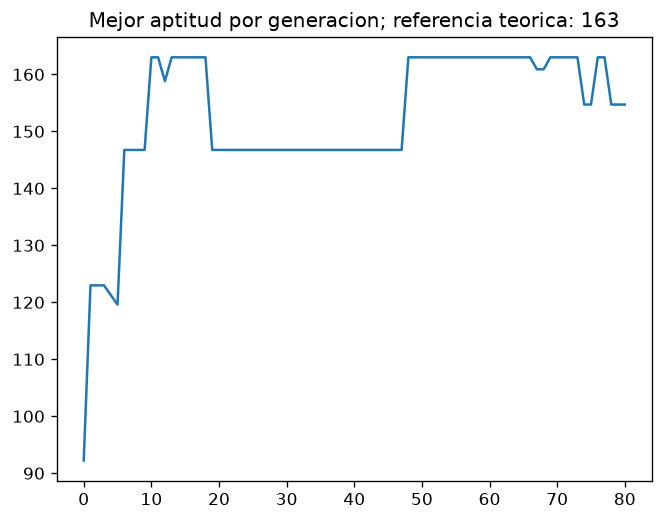

In [8]:
import numpy as np
import matplotlib.pyplot as plt


def F(x):
    return 2 * x**4 + 1


def translateDNA(pop):
    pesos = 2**np.arange(bits)[::-1]
    return a + (b - a) * pop.dot(pesos) / (2**bits - 1)


def select(pop, fitness):
    p = fitness / fitness.sum()
    acumulada = np.cumsum(p)
    seleccionados = pop.copy()
    for i in range(len(pop)):
        u = np.random.rand()
        j = 0
        while j < len(pop) - 1 and u >= acumulada[j]:
            j = j + 1
        seleccionados[i] = pop[j]
    return seleccionados


def crossover_(padre_1, padre_2, corte):
    hijo_1 = np.concatenate((padre_1[:corte], padre_2[corte:]))
    hijo_2 = np.concatenate((padre_2[:corte], padre_1[corte:]))
    return hijo_1, hijo_2


def mutate(hijo):
    for j in range(len(hijo)):
        if np.random.rand() < pm:
            hijo[j] = 1 - hijo[j]
    return hijo


a = -2
b = 3
precision = 0.01
bits = 1
while (b - a) / (2**bits - 1) > precision:
    bits = bits + 1

n = 20
pc = 0.8
pm = 0.01
generaciones = 80
pop = np.random.randint(2, size=(n, bits))
mejores = np.zeros(generaciones + 1)
mejores[0] = np.max(F(translateDNA(pop)))

for t in range(generaciones):
    fitness = F(translateDNA(pop))
    padres = select(pop, fitness)
    nueva = padres.copy()

    for i in range(0, n, 2):
        hijo_1 = padres[i].copy()
        hijo_2 = padres[i + 1].copy()
        if np.random.rand() < pc:
            corte = np.random.randint(1, bits)
            hijo_1, hijo_2 = crossover_(padres[i], padres[i + 1], corte)
        nueva[i] = mutate(hijo_1)
        nueva[i + 1] = mutate(hijo_2)

    pop = nueva
    mejores[t + 1] = np.max(F(translateDNA(pop)))

x = translateDNA(pop)
valores = F(x)
indice = np.argmax(valores)
print("Bits:", bits)
print("Paso de la malla:", (b - a) / (2**bits - 1))
print("Mejor cromosoma final:", pop[indice])
print("Mejor x de la poblacion final:", x[indice])
print("Valor encontrado:", valores[indice])
print("Maximo teorico de referencia:", F(b))
plt.plot(np.arange(generaciones + 1), mejores)
plt.title("Mejor aptitud por generacion; referencia teorica: 163")
plt.show()




## Explicación del código por bloques

**`F` y `translateDNA`: evaluar no es seleccionar.** La primera función calcula
la aptitud de los reales. La segunda convierte filas binarias a reales: las
potencias descendentes corresponden al peso de cada bit y `.dot(pesos)` obtiene
el entero de cada fila. El factor `(b-a)` y el término `a` son ambos necesarios.
Así se evita el error de multiplicar solo por el extremo superior, que puede
terminar buscando en un intervalo distinto al anunciado.

**`select`: copiar padres con probabilidad proporcional.** Primero normaliza
las aptitudes y construye la acumulada. Luego hace veinte sorteos y copia en
cada fila al individuo elegido. `seleccionados=pop.copy()` reserva una población
independiente: escribir una fila de salida no debe alterar las filas de entrada
que todavía pueden seleccionarse. Algunos padres pueden repetirse y otros no
aparecer; eso es justamente selección con reemplazo.

**`crossover_`: dos resultados de un mismo evento.** Recibe dos filas y un corte
interior ya elegido, y devuelve los hijos complementarios. Al recorrer parejas
con `range(0,n,2)`, el programa usa las filas 0–1, 2–3, y así sucesivamente.
Hace UN sorteo para decidir si cruza esa pareja y UN corte para ambos hijos.
Elegir un padre y un corte independientes para cada hijo sería otro mecanismo,
no el cruzamiento simple cuya estructura estamos practicando.

**`mutate`: un sorteo por gen.** Recorre cada posición del hijo e invierte su
bit cuando el uniforme es menor que `pm`. Se llama por separado para ambos
descendientes, por lo que cada uno tiene sus propias decisiones de mutación.
Cuando no se cruza la pareja se conservan copias de sus padres, pero esas copias
todavía pasan por mutación; «no cruzar» no significa «no aplicar ningún operador».

**Inicialización y ciclo.** `randint(2,size=(n,bits))` crea veinte filas de nueve
bits sin imponer una semilla. El ciclo evalúa la población actual, selecciona
padres, construye por completo la población siguiente y solo después hace
`pop=nueva`. Separar `padres` de `nueva` evita que un hijo ya generado se use por
accidente como padre de otra pareja dentro de la misma generación.

**Historial y gráfico.** `mejores[0]` corresponde a la población inicial.
Después de cada reemplazo se evalúa la nueva población y se guarda su mayor
aptitud en `mejores[t+1]`. Por eso hay 81 valores para las generaciones 0 a 80,
sin desplazar la gráfica una generación respecto a los datos. El gráfico muestra
mejor aptitud ACTUAL, no mejor histórico garantizado. No se usa elitismo para
forzar que la curva sea creciente; eso introduciría una característica excluida.

**Resultado final.** `np.argmax(valores)` entrega la posición del mejor miembro
de la población FINAL, no su aptitud. Con ese índice se imprimen su cadena,
su valor real y su aptitud. El máximo teórico 163 se muestra aparte, claramente
rotulado. No se anuncia como resultado encontrado si el algoritmo obtiene menos.

## Qué concluir de una ejecución

Si obtiene 163, encontró el óptimo de este ejercicio. Si termina por debajo,
encontró una aproximación o convergió a una región subóptima; no se debe falsificar
la salida ni afirmar que un algoritmo genético garantiza el máximo en 80 pasos.
La curva puede descender porque el mejor miembro puede perderse al seleccionar,
cruzar o mutar. Una curva plana tampoco prueba optimalidad sin compararla con la
referencia analítica, y volver a ejecutar puede producir resultados distintos.

El tope de 80 generaciones es el criterio de parada dado. Se evalúan la población
inicial y ochenta poblaciones siguientes; repetir ciertos cálculos de aptitud en
el código no significa haber generado generaciones adicionales. No se incorporan
paradas adaptativas, múltiples ensayos comparativos o métricas adicionales que
el enunciado no solicita.

## Cómo adaptar el ejercicio a otra función

Cambiar la función puede obligar a revisar la aptitud, no solo reemplazar `F`.
Si toma valores negativos, ya no sirve automáticamente una ruleta proporcional
a esos valores. Si cambia el intervalo o la precisión, deben recalcularse bits
y mapeo. Si piden minimización, seleccionar más a los valores grandes de la
función original sería lo contrario de lo requerido. Primero identifica qué
debe favorecer la selección y después adapta el código; no traslades una plantilla
sin verificar las premisas del problema.


# Cierre: qué debes poder explicar sin mirar el código

- Qué cuenta cada bucle: una selección, una población o una generación.
- Por qué una esperanza puede ser decimal y una cantidad observada de copias no.
- De dónde salen las potencias dos y tres al contar cadenas y esquemas.
- Cómo obtener representantes, orden y longitud definitoria antes de usar una cota.
- Por qué la codificación usa el ancho del intervalo y el denominador $2^l-1$.
- Por qué un mismo cruce produce dos hijos, independientemente del tamaño poblacional.
- Por qué no se garantiza llegar al máximo con un número finito de generaciones.

**No memorices solamente números.** Si cambian los datos, identifica qué cantidades
se recalculan y qué procedimiento permanece igual. Los apartados de adaptación
al final de cada pregunta están para practicar justamente esa transferencia.
